In [1]:
import torch

In [2]:
X = torch.tensor([
    [1.0, 2.0],
    [2.0, 3.0],
    [3.0, 2.0],
    [4.0, 4.0],

    [-1.0, -2.0],
    [-2.0, -3.0],
    [-3.0, -2.0],
    [-4.0, -4.0]
])

In [3]:
y = torch.tensor([
     -1.0,
     1.0,
     1.0,
     1.0,

    -1.0,
    -1.0,
    -1.0,
    -1.0
])

In [4]:
X= torch.cat(
    (
        torch.ones(X.shape[0], 1),
        X
    ),
    dim=1
)
X

tensor([[ 1.,  1.,  2.],
        [ 1.,  2.,  3.],
        [ 1.,  3.,  2.],
        [ 1.,  4.,  4.],
        [ 1., -1., -2.],
        [ 1., -2., -3.],
        [ 1., -3., -2.],
        [ 1., -4., -4.]])

In [20]:

class Perceptron:

  def __init__(self,learnig_rate,epochs):
    self.learnig_rate=learnig_rate
    self.epochs=epochs
    self.W=None
    self.loss_history=[]

  def loss_function(self,y_true,z):
    loss=torch.maximum(
        torch.tensor(0.0),-y_true*z
    )
    return loss

  def fit(self,X,y):
    n_samples,n_features=X.shape
    # initialize weight
    self.W=torch.zeros(n_features)

    for epoch in range(self.epochs):
      total_loss=0
      for i in range(n_samples):
        x_i=X[i]
        y_i=y[i]

        z=torch.dot(self.W,x_i)

        loss=self.loss_function(y_i,z)
        total_loss+=loss.item()

        # update weight
        if y_i*z<=0:
          self.W=self.W+self.learnig_rate*y_i*x_i

      mean_loss=total_loss/n_samples
      self.loss_history.append(mean_loss)
      print(f'Epoch:{epoch+1}| loss:{mean_loss}| W : {self.W}')

  def predit(self,X):
    z=torch.matmul(X,self.W)

    y_pred=torch.where(
        z>=0,
        torch.tensor(1.0),
        torch.tensor(-1.0)
    )
    return y_pred




In [21]:
model=Perceptron(0.1,20)
model.fit(X,y)

Epoch:1| loss:0.11250000447034836| W : tensor([0.0000, 0.1000, 0.1000])
Epoch:2| loss:0.08749999850988388| W : tensor([0.0000, 0.2000, 0.2000])
Epoch:3| loss:0.07500000298023224| W : tensor([-1.0000e-01,  1.0000e-01,  1.4901e-08])
Epoch:4| loss:0.09999999776482582| W : tensor([-0.1000,  0.2000,  0.1000])
Epoch:5| loss:0.07499999925494194| W : tensor([-0.1000,  0.3000,  0.2000])
Epoch:6| loss:0.07500001043081284| W : tensor([-2.0000e-01,  2.0000e-01,  2.9802e-08])
Epoch:7| loss:0.08749999292194843| W : tensor([-0.2000,  0.3000,  0.1000])
Epoch:8| loss:0.0624999925494194| W : tensor([-0.2000,  0.4000,  0.2000])
Epoch:9| loss:0.07500001788139343| W : tensor([-3.0000e-01,  3.0000e-01,  4.4703e-08])
Epoch:10| loss:0.07499998807907104| W : tensor([-0.3000,  0.4000,  0.1000])
Epoch:11| loss:0.049999985843896866| W : tensor([-0.3000,  0.5000,  0.2000])
Epoch:12| loss:0.07500001788139343| W : tensor([-4.0000e-01,  4.0000e-01,  5.9605e-08])
Epoch:13| loss:0.062499985098838806| W : tensor([-0.400

In [22]:
y_pred=model.predit(X)
y_pred

tensor([-1.,  1.,  1.,  1., -1., -1., -1., -1.])

In [23]:
y

tensor([-1.,  1.,  1.,  1., -1., -1., -1., -1.])

In [28]:
accuracy=(y_pred==y).sum()/(len(y))
accuracy


tensor(1.)

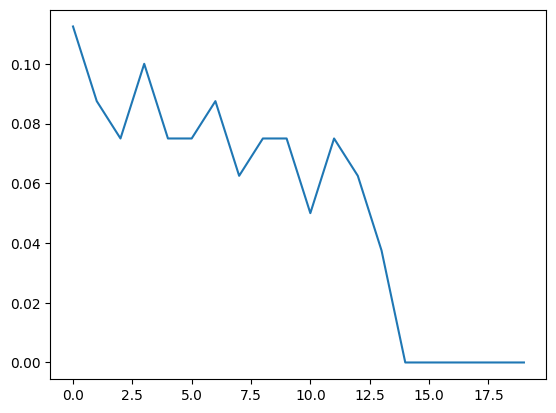

In [27]:
import matplotlib.pyplot as plt

plt.plot(range(0,20),model.loss_history)
plt.show()

In [25]:
range(0,20)

range(0, 20)

In [26]:
model.loss_history

[0.11250000447034836,
 0.08749999850988388,
 0.07500000298023224,
 0.09999999776482582,
 0.07499999925494194,
 0.07500001043081284,
 0.08749999292194843,
 0.0624999925494194,
 0.07500001788139343,
 0.07499998807907104,
 0.049999985843896866,
 0.07500001788139343,
 0.062499985098838806,
 0.03750002384185791,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0]